# 02 · Modelado y evaluación · Dry Bean Dataset
**Rol:** ML Engineer · **Sprint 2** · **Backlog:** PB-03 (Logistic Regression), PB-04 (Random Forest), PB-05 (comparar métricas)

| Fase CRISP-DM | Dónde en este notebook |
|---|---|
| 4. Modelado | Secciones 2 a 4 |
| 5. Evaluación | Secciones 5 a 8 |

**TDSP:** los datos salen de `data/processed/` (Sprint 1), la lógica reutilizable vive en `src/models.py` y `src/evaluate.py` (con pruebas en `tests/`) y la evidencia queda en `outputs/reports/`.

**Regla de oro:** el conjunto de *test* no se usa para decidir nada. Las decisiones (modelo, hiperparámetros) se toman con validación cruzada **solo sobre train**; el test solo informa el desempeño final.

In [1]:
import os
from pathlib import Path

# El notebook vive en notebooks/; las rutas del proyecto son relativas a la raíz
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from src.evaluate import (compare_models, cross_validate_model, evaluate_model,
                          plot_confusion_matrix)
from src.models import build_baseline, build_random_forest, load_train_test
from src.preprocessing import RANDOM_STATE

REPORTS = Path("outputs/reports")
REPORTS.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)

# Trazabilidad TDSP: versiones con las que se obtuvieron los resultados
import sys, sklearn
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}")

Python 3.13.5 | scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.4


## 1. Datos de entrada
Se leen los CSV que dejó el Data Engineer: 80/20 estratificado, `random_state=42`, sin duplicados.

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
assert X_train.shape == (10834, 16) and X_test.shape == (2709, 16)
print("train:", X_train.shape, "| test:", X_test.shape)
pd.concat([y_train.value_counts(normalize=True).rename("train"),
           y_test.value_counts(normalize=True).rename("test")], axis=1).round(3)

train: (10834, 16) | test: (2709, 16)


,train,test
Class,,
DERMASON,0.262,0.262
SIRA,0.195,0.195
SEKER,0.150,0.150
HOROZ,0.137,0.137
CALI,0.120,0.120
BARBUNYA,0.098,0.098
BOMBAY,0.039,0.038


## 2. PB-03 · Baseline: Regresión Logística (pasos 9 y 10 del laboratorio)
Un *baseline* es un primer modelo sencillo que sirve de punto de comparación: si un modelo más complejo no lo mejora, quizá no vale la pena usarlo. Va en un `Pipeline` con `StandardScaler` (`build_preprocessor()`), que se ajusta **solo con train** para no filtrar información del test.

In [3]:
baseline = build_baseline().fit(X_train, y_train)
res_base = evaluate_model(baseline, X_test, y_test)
print(f"Accuracy baseline : {res_base['accuracy']:.4f}")
print(f"F1 macro baseline : {res_base['f1_macro']:.4f}")
print(pd.DataFrame(res_base["report"]).T.round(3))

Accuracy baseline : 0.9195
F1 macro baseline : 0.9306
              precision  recall  f1-score  support
BARBUNYA          0.925   0.891     0.908   265.00
BOMBAY            1.000   1.000     1.000   104.00
CALI              0.911   0.942     0.926   326.00
DERMASON          0.927   0.907     0.917   709.00
HOROZ             0.964   0.944     0.954   372.00
SEKER             0.932   0.943     0.938   406.00
SIRA              0.858   0.886     0.872   527.00
accuracy          0.920   0.920     0.920     0.92
macro avg         0.931   0.930     0.931  2709.00
weighted avg      0.920   0.920     0.920  2709.00


**Pregunta (paso 10):** ¿por qué F1 macro es más informativo que accuracy con clases desbalanceadas?

Porque accuracy cuenta aciertos en bloque y las clases grandes dominan el resultado: `DERMASON` (3.546 granos) pesa ~7 veces más que `BOMBAY` (522). Un modelo que fallara siempre en la clase minoritaria seguiría teniendo un accuracy alto. F1 macro calcula el F1 de cada clase y los promedia con el **mismo peso**, así que castiga los errores en clases pequeñas igual que en las grandes.

## 3. PB-04 · Random Forest (pasos 11 y 12)
200 árboles con `class_weight="balanced"`, que compensa el desbalance. Random Forest no necesita escalado (los árboles dividen por umbrales), pero se compara contra el baseline para justificar su uso.

In [4]:
forest = build_random_forest().fit(X_train, y_train)
res_rf = evaluate_model(forest, X_test, y_test)
print(f"Accuracy Random Forest : {res_rf['accuracy']:.4f}")
print(f"F1 macro Random Forest : {res_rf['f1_macro']:.4f}")
print(pd.DataFrame(res_rf["report"]).T.round(3))

Accuracy Random Forest : 0.9195
F1 macro Random Forest : 0.9310
              precision  recall  f1-score  support
BARBUNYA          0.922   0.898     0.910   265.00
BOMBAY            1.000   1.000     1.000   104.00
CALI              0.921   0.936     0.928   326.00
DERMASON          0.920   0.910     0.915   709.00
HOROZ             0.964   0.946     0.955   372.00
SEKER             0.924   0.958     0.941   406.00
SIRA              0.866   0.869     0.867   527.00
accuracy          0.920   0.920     0.920     0.92
macro avg         0.931   0.931     0.931  2709.00
weighted avg      0.920   0.920     0.920  2709.00


## 4. Búsqueda de hiperparámetros (extensión B)
`GridSearchCV` sobre Random Forest con `scoring="f1_macro"` y validación cruzada estratificada de 5 pliegues, **solo con train**.

In [5]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    build_random_forest(),
    param_grid={"classifier__n_estimators": [200, 400],
                "classifier__max_depth": [None, 10, 20],
                "classifier__min_samples_split": [2, 5, 10]},
    scoring="f1_macro", cv=cv5, n_jobs=-1,
).fit(X_train, y_train)

print("Mejores parámetros:", grid.best_params_)
print(f"F1 macro CV (mejor): {grid.best_score_:.4f}")
forest_tuned = grid.best_estimator_
res_rf_tuned = evaluate_model(forest_tuned, X_test, y_test)
print(f"Test -> accuracy {res_rf_tuned['accuracy']:.4f} | F1 macro {res_rf_tuned['f1_macro']:.4f}")

Mejores parámetros: {'classifier__max_depth': 20, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 400}
F1 macro CV (mejor): 0.9354


Test -> accuracy 0.9192 | F1 macro 0.9308


## 5. PB-05 · Comparación de modelos (paso 13)
Además de accuracy y F1 macro en test se agrega la **validación cruzada sobre train** (media ± desviación): en este dataset los modelos quedan muy cerca y la desviación dice si la diferencia es real o ruido.

In [6]:
modelos = {
    "Logistic Regression": (build_baseline, baseline, res_base),
    "Random Forest": (build_random_forest, forest, res_rf),
}
resultados = {}
for nombre, (builder, _, res) in modelos.items():
    cv = cross_validate_model(builder(), X_train, y_train, cv=5)
    resultados[nombre] = {"accuracy": res["accuracy"], "f1_macro": res["f1_macro"], **cv}

i = grid.best_index_
resultados["Random Forest (ajustado)"] = {
    "accuracy": res_rf_tuned["accuracy"], "f1_macro": res_rf_tuned["f1_macro"],
    "cv_f1_macro_mean": float(grid.cv_results_["mean_test_score"][i]),
    "cv_f1_macro_std": float(grid.cv_results_["std_test_score"][i]),
}
comparacion = compare_models(resultados, REPORTS / "comparacion_modelos.csv")
comparacion.round(4)

,modelo,accuracy,f1_macro,cv_f1_macro_mean,cv_f1_macro_std
0,Logistic Regression,0.9195,0.9306,0.9365,0.0037
1,Random Forest,0.9195,0.9310,0.9343,0.0047
2,Random Forest (ajustado),0.9192,0.9308,0.9354,0.0043


## 6. Decisión del modelo (fase de Evaluación de CRISP-DM)
Criterio del laboratorio:
1. Priorizar F1 macro.
2. Revisar los errores por clase.
3. Si el desempeño es muy parecido, preferir el modelo más simple.

La decisión se toma con la **validación cruzada sobre train** (el test queda como evidencia independiente). Dos modelos se consideran equivalentes si la diferencia de sus medias es menor que la mayor de sus desviaciones.

In [7]:
complejidad = ["Logistic Regression", "Random Forest", "Random Forest (ajustado)"]  # de más simple a más complejo
cv = comparacion.set_index("modelo")
mejor_cv = cv["cv_f1_macro_mean"].max()
mejor = cv["cv_f1_macro_mean"].idxmax()
umbral = cv.loc[mejor, "cv_f1_macro_std"]
equivalentes = [m for m in complejidad if mejor_cv - cv.loc[m, "cv_f1_macro_mean"] <= umbral]
modelo_final = equivalentes[0]   # el más simple entre los equivalentes

print(f"Mejor F1 macro en CV: {mejor} ({mejor_cv:.4f} ± {umbral:.4f})")
print("Equivalentes (dentro de 1 desviación):", equivalentes)
print("Modelo elegido:", modelo_final)

finales = {"Logistic Regression": baseline, "Random Forest": forest,
           "Random Forest (ajustado)": forest_tuned}
res_final = {"Logistic Regression": res_base, "Random Forest": res_rf,
             "Random Forest (ajustado)": res_rf_tuned}

Mejor F1 macro en CV: Logistic Regression (0.9365 ± 0.0037)
Equivalentes (dentro de 1 desviación): ['Logistic Regression', 'Random Forest', 'Random Forest (ajustado)']
Modelo elegido: Logistic Regression


## 7. Matrices de confusión y errores por clase (paso 14)

In [8]:
fig_lr = plot_confusion_matrix(y_test, res_base["y_pred"], "Matriz de confusión · Logistic Regression",
                               REPORTS / "matriz_confusion_logreg.png")
fig_rf = plot_confusion_matrix(y_test, res_rf["y_pred"], "Matriz de confusión · Random Forest",
                               REPORTS / "matriz_confusion_rf.png")
display(fig_lr); display(fig_rf)

<Figure size 800x600 with 1 Axes>

<Figure size 800x600 with 1 Axes>

In [9]:
def pares_confundidos(y_true, y_pred, n=6):
    cm = pd.crosstab(pd.Series(y_true, name="real").reset_index(drop=True),
                     pd.Series(y_pred, name="predicha"))
    filas = [(r, p, int(cm.loc[r, p])) for r in cm.index for p in cm.columns
             if r != p and cm.loc[r, p] > 0]
    return (pd.DataFrame(filas, columns=["real", "predicha", "errores"])
            .sort_values("errores", ascending=False).head(n).reset_index(drop=True))

print("Logistic Regression"); display(pares_confundidos(y_test, res_base["y_pred"]))
print("Random Forest"); display(pares_confundidos(y_test, res_rf["y_pred"]))

f1_clase = pd.DataFrame({
    "LogReg": {c: res_base["report"][c]["f1-score"] for c in sorted(y_test.unique())},
    "RandomForest": {c: res_rf["report"][c]["f1-score"] for c in sorted(y_test.unique())},
}).round(3)
f1_clase

Logistic Regression


,real,predicha,errores
0,DERMASON,SIRA,53
1,SIRA,DERMASON,41
2,BARBUNYA,CALI,18
3,DERMASON,SEKER,13
4,HOROZ,CALI,11
5,SEKER,SIRA,9


Random Forest


,real,predicha,errores
0,SIRA,DERMASON,48
1,DERMASON,SIRA,47
2,DERMASON,SEKER,17
3,BARBUNYA,CALI,17
4,CALI,BARBUNYA,11
5,SIRA,SEKER,10


,LogReg,RandomForest
BARBUNYA,0.908,0.910
BOMBAY,1.000,1.000
CALI,0.926,0.928
DERMASON,0.917,0.915
HOROZ,0.954,0.955
SEKER,0.938,0.941
SIRA,0.872,0.867


## 8. Interpretación del modelo (paso 15)
Con variables muy colineales (`Area`–`ConvexArea`, `Compactness`–`ShapeFactor3`) la importancia por impureza de Random Forest se **reparte entre las variables gemelas** y puede engañar. Por eso se cruza con la **importancia por permutación sobre test** (cuánto baja el F1 macro al barajar una variable). Ninguna de las dos prueba causalidad.

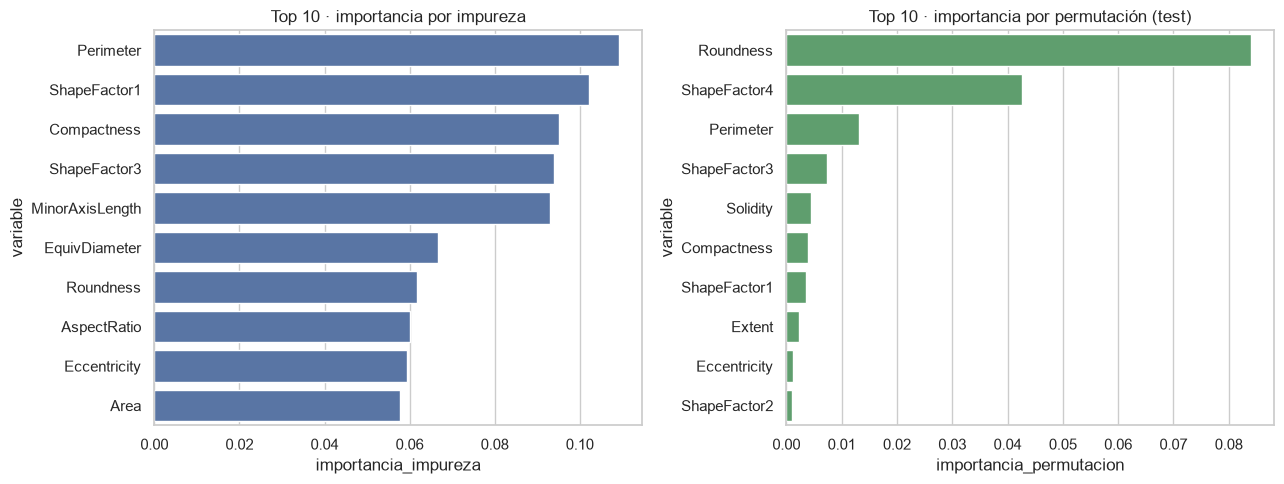

,variable,importancia_impureza,importancia_permutacion
0,Perimeter,0.1092,0.0132
1,ShapeFactor1,0.1021,0.0035
2,Compactness,0.0952,0.0038
3,ShapeFactor3,0.0939,0.0073
4,MinorAxisLength,0.0929,0.0003
5,EquivDiameter,0.0667,0.0002
6,Roundness,0.0618,0.0840
7,AspectRatio,0.0600,0.0004
8,Eccentricity,0.0593,0.0011
9,Area,0.0578,0.0003


In [10]:
imp = pd.DataFrame({
    "variable": X_train.columns,
    "importancia_impureza": forest.named_steps["classifier"].feature_importances_,
})
perm = permutation_importance(forest, X_test, y_test, scoring="f1_macro",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp["importancia_permutacion"] = perm.importances_mean
imp = imp.sort_values("importancia_impureza", ascending=False).reset_index(drop=True)
imp.to_csv(REPORTS / "importancia_variables.csv", index=False)

top = imp.head(10)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=top, y="variable", x="importancia_impureza", ax=axes[0], color="#4C72B0")
axes[0].set_title("Top 10 · importancia por impureza")
top_p = imp.sort_values("importancia_permutacion", ascending=False).head(10)
sns.barplot(data=top_p, y="variable", x="importancia_permutacion", ax=axes[1], color="#55A868")
axes[1].set_title("Top 10 · importancia por permutación (test)")
fig.tight_layout()
fig.savefig(REPORTS / "importancia_variables.png", dpi=150)
plt.show()
imp.head(10).round(4)

In [11]:
# Coeficientes de la regresión logística (variables estandarizadas): |coef| medio entre clases
coef = baseline.named_steps["classifier"].coef_
coef_df = (pd.DataFrame(np.abs(coef).mean(axis=0), index=X_train.columns, columns=["|coef| medio"])
           .sort_values("|coef| medio", ascending=False))
coef_df.head(10).round(3)

,|coef| medio
ShapeFactor1,1.771
MinorAxisLength,1.313
ShapeFactor2,1.251
ShapeFactor4,1.195
Perimeter,1.070
EquivDiameter,1.051
Roundness,0.979
MajorAxisLength,0.968
ConvexArea,0.966
Area,0.944


## 9. Archivo de predicciones (extensión C)
Predicciones del modelo elegido sobre test, con la clase real, para el análisis de errores del Data Engineer.

In [12]:
pred_final = res_final[modelo_final]["y_pred"]
predicciones = X_test.copy()
predicciones["real_class"] = y_test.values
predicciones["predicted_class"] = pred_final
predicciones.to_csv(REPORTS / "predicciones_drybean.csv", index=False)
print(f"Modelo: {modelo_final} | filas: {len(predicciones)} | errores: "
      f"{int((predicciones['real_class'] != predicciones['predicted_class']).sum())}")

Modelo: Logistic Regression | filas: 2709 | errores: 218


## 10. Conclusiones y respuestas a las preguntas del laboratorio

**Resultados** (test = 2.709 granos; CV = 5 pliegues sobre train)

| Modelo | Accuracy | F1 macro | F1 macro CV |
|---|---|---|---|
| Logistic Regression (baseline) | 0,9195 | 0,9306 | 0,9365 ± 0,0037 |
| Random Forest | 0,9195 | 0,9310 | 0,9343 ± 0,0047 |
| Random Forest ajustado (`max_depth=20`, `n_estimators=400`) | 0,9192 | 0,9308 | 0,9354 ± 0,0043 |

**Decisión: se elige la Regresión Logística.** Las diferencias entre los tres modelos son de 0,0004 en F1 macro sobre test y de 0,002 en validación cruzada, menores que la desviación entre pliegues (≈ 0,004): es ruido, no una mejora real. Random Forest, ni siquiera ajustado, supera al baseline. Con desempeño equivalente el laboratorio pide preferir el modelo más simple, que además es más rápido, pequeño e interpretable (coeficientes).

**¿Qué clases se confunden más?**
- **DERMASON ↔ SIRA** (94 errores en la regresión logística, 95 en Random Forest, ~43 % de los errores). Tienen forma casi igual (relación de aspecto mediana 1,48 vs 1,56; solidez 0,989 en ambas) y se diferencian sobre todo por tamaño (área mediana 31.874 vs 44.659 px²), con solapamiento. `SIRA` es la clase con peor F1 (0,87).
- **BARBUNYA ↔ CALI** (≈ 17–19 errores por sentido): áreas medianas parecidas (69.509 vs 74.629 px²).
- `BOMBAY` se clasifica sin errores (F1 = 1,00): es mucho más grande que el resto (área mediana 171.224 px²).

**Importancia de variables.** La importancia por impureza reparte el peso entre variables colineales (`Perimeter`, `ShapeFactor1`, `Compactness`, `ShapeFactor3`), mientras que la de permutación señala a `Roundness` como la que más cae el F1 al barajarla (0,084), muy por encima del resto. Las variables de tamaño gemelas (`Area`, `EquivDiameter`) casi no pierden al permutarse porque las otras las reemplazan: es redundancia, no irrelevancia. La importancia no implica causalidad.

**Preguntas de reflexión del ML Engineer**
- *¿Por qué un baseline?* Es el punto de comparación: aquí mostró que la complejidad extra de Random Forest no aporta.
- *¿Qué métrica usar?* F1 macro, porque pondera igual a `BOMBAY` (522 granos) y a `DERMASON` (3.546).
- *¿Qué hacer si una clase falla más (`SIRA`)?* Revisar sus errores con el EDA, añadir variables que separen mejor de `DERMASON`, probar pesos de clase o más muestras, y evaluar modelos no lineales con mejor margen.
- *¿Qué falta para producción?* Misma cámara, calibración y segmentación que en el entrenamiento (las medidas están en píxeles), monitoreo de deriva de las variables, umbral de confianza para derivar a revisión manual y pruebas con un lote nuevo.

**Limitaciones.** Un único split 80/20 y un solo dataset; el modelo final aún **no está guardado** (se hace en el Sprint 3 con `joblib`, guardando el `Pipeline` completo).